In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Configuring display settings
plt.rcParams['figure.figsize'] = (12, 9)
sns.set()
sns.set_context('talk')
np.set_printoptions(threshold=20, precision=2, suppress=True)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 2)
pd.set_option('display.float_format', '{:.2f}'.format)
warnings.filterwarnings("ignore", category=FutureWarning)
import json

In [14]:
# Import config variable
with open("../../config.json") as f:
    cfg = json.load(f)
    
target = cfg["rc"]        
file_name = cfg["rc_file_name"]   
random_state = cfg["split"]["random_state"]  
# Load the dataset
data = pd.read_csv(f"../../data/{file_name}.csv")

In [ ]:
from sklearn.model_selection import GroupShuffleSplit
import numpy as np

X = data.drop(columns=[target])
y = data[target]

# Tirage de 4 seeds aléatoires différentes
master_rng = np.random.default_rng(seed=99)
seeds = master_rng.choice(10000, size=4, replace=False).tolist()
print("Seeds sélectionnées :", seeds)

# Split groupé par formulation : toutes les lignes d'une même formulation
# (4 âges + copies synthétiques éventuelles) vont du même côté
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=X['formulation_id']))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = X_train['formulation_id']          # pour le GroupKFold du GridSearch

# Test : uniquement les vraies lignes (si data augmentation)
if 'is_synthetic' in X_test.columns:
    mask = X_test['is_synthetic'].eq(0)
    X_test, y_test = X_test[mask], y_test[mask]

# Train réel, pour les métriques train
if 'is_synthetic' in X_train.columns:
    real_mask = X_train['is_synthetic'].eq(0)
else:
    real_mask = np.ones(len(X_train), dtype=bool)
X_tr_real, y_tr_real = X_train[real_mask], y_train[real_mask]

# Retrait des colonnes qui ne sont pas des features
non_features = ['formulation_id', 'is_synthetic']
X_train   = X_train.drop(columns=non_features, errors='ignore')
X_test    = X_test.drop(columns=non_features, errors='ignore')
X_tr_real = X_tr_real.drop(columns=non_features, errors='ignore')

print("Split groupé OK :", set(groups_train).isdisjoint(X.iloc[test_idx]['formulation_id']))
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples (réelles uniquement)")
print("Features :", list(X_train.columns))

Seeds sélectionnées : [5650, 7575, 5059, 9578]
Split groupé OK : True
Training set size: 968 samples
Test set size: 62 samples (réelles uniquement)
Features : ['chanvre 5', 'chanvre 15', 'bambou 5', 'bambou 15', 'lin 5', 'lin 6', 'lin 15', 'miscanthus 5', 'miscanthus 15', 'Days', 'Slump (mm)', 'Air occluded (%)', 'Volumic mass (kg/m3)', 'Aspect ratio (L/D) soft fibers', 'Aspect ratio (L/D) rigid fibers', 'Absorption coefficient t=2880s soft fibers', 'Absorption coefficient t=2880s rigid fibers']


Split groupé OK : True
Features : ['chanvre 5', 'chanvre 15', 'bambou 5', 'bambou 15', 'lin 5', 'lin 6', 'lin 15', 'miscanthus 5', 'miscanthus 15', 'Days', 'Slump (mm)', 'Air occluded (%)', 'Volumic mass (kg/m3)', 'Aspect ratio (L/D) soft fibers', 'Aspect ratio (L/D) rigid fibers', 'Absorption coefficient t=2880s soft fibers', 'Absorption coefficient t=2880s rigid fibers']
{'max_depth': 6, 'max_features': 0.5, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 200}
MAE (test): 1.68629090626976
RMSE (test): 2.152144028513982
R² (test): 0.9271180614876824
 
MAE (train): 1.2394875992638745
RMSE (train): 1.5838625625647804
R² (train): 0.9625217143413816


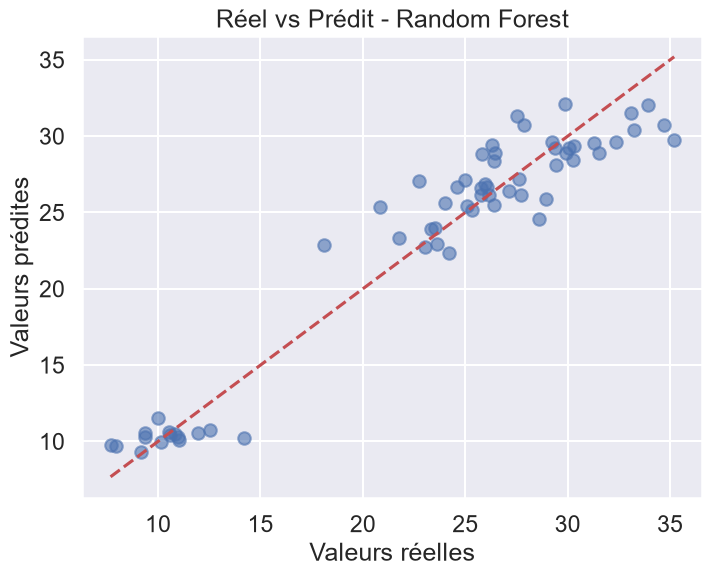

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# Utilise le split du bloc précédent :
# X_train, y_train, X_test, y_test, X_tr_real, y_tr_real, groups_train

# --- GridSearch avec CV groupée ---
param_grid = {
    'n_estimators': [200, 300, 500],
    'max_depth': [None, 6, 8, 10],          # None = pas de limite
    'min_samples_leaf': [1, 2, 4],
    'min_samples_split': [2, 5, 10],
    'max_features': ['sqrt', 0.3, 0.5, 0.7],
}
grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid,
                           cv=GroupKFold(n_splits=5), scoring='r2', n_jobs=-1)
grid_search.fit(X_train, y_train, groups=groups_train)
print(grid_search.best_params_)
best_model = grid_search.best_estimator_

# --- Évaluation sur le test set (vraies lignes uniquement) ---
y_pred = best_model.predict(X_test)
print("MAE (test):", mean_absolute_error(y_test, y_pred))
print("RMSE (test):", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R² (test):", r2_score(y_test, y_pred))
print(" ")

# --- Évaluation sur le train set (vraies lignes uniquement) ---
y_tr_pred = best_model.predict(X_tr_real)
print("MAE (train):", mean_absolute_error(y_tr_real, y_tr_pred))
print("RMSE (train):", np.sqrt(mean_squared_error(y_tr_real, y_tr_pred)))
print("R² (train):", r2_score(y_tr_real, y_tr_pred))

# --- Visualisation réel vs prédit ---
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title('Réel vs Prédit - Random Forest')
plt.show()

In [ ]:
import joblib
joblib.dump(best_model, 'saved_models/random_forest_rc.pkl')

['saved_models/random_forest_rc.pkl']

In [ ]:
import joblib
import os
import numpy as np
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

os.makedirs('saved_models', exist_ok=True)

# Utilise le split du bloc précédent :
# X_train, y_train, X_test, y_test, X_tr_real, y_tr_real, groups_train, seeds

param_grid = {
    'n_estimators': [200, 300, 500],
    'max_depth': [None, 6, 8, 10],
    'min_samples_leaf': [1, 2, 4],
    'min_samples_split': [2, 5, 10],
    'max_features': ['sqrt', 0.3, 0.5, 0.7],
}

results_per_seed = {}

for seed in seeds:
    print(f"\n{'='*50}")
    print(f"Entraînement Random Forest avec seed = {seed}")
    print(f"{'='*50}")

    gs = GridSearchCV(
        RandomForestRegressor(random_state=seed),
        param_grid,
        cv=GroupKFold(n_splits=5),
        scoring='r2',
        n_jobs=-1,
        verbose=0
    )
    gs.fit(X_train, y_train, groups=groups_train)
    print(f"Meilleurs params : {gs.best_params_}")

    model_s = gs.best_estimator_

    y_pred_s = model_s.predict(X_test)
    r2_test  = r2_score(y_test, y_pred_s)
    mae_test = mean_absolute_error(y_test, y_pred_s)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_s))
    r2_train = r2_score(y_tr_real, model_s.predict(X_tr_real))

    print(f"R² train : {r2_train:.4f}")
    print(f"R² test  : {r2_test:.4f}")
    print(f"MAE test : {mae_test:.4f}")
    print(f"RMSE test: {rmse_test:.4f}")

    results_per_seed[seed] = {
        "r2_train":    r2_train,
        "r2_test":     r2_test,
        "mae_test":    mae_test,
        "rmse_test":   rmse_test,
        "best_params": gs.best_params_,
    }

    joblib.dump(model_s, f'saved_models/random_forest_seed_{seed}.pkl')
    print(f"  -> saved_models/random_forest_seed_{seed}.pkl")

print("\n\n=== Récapitulatif ===")
for s, m in results_per_seed.items():
    print(f"seed={s:5d}  R²_train={m['r2_train']:.4f}  R²_test={m['r2_test']:.4f}  MAE={m['mae_test']:.4f}  RMSE={m['rmse_test']:.4f}")

for k in ['r2_train', 'r2_test', 'mae_test', 'rmse_test']:
    v = np.array([m[k] for m in results_per_seed.values()])
    print(f"{k:10s} : {v.mean():.4f} ± {v.std(ddof=1):.4f}")

Seeds sélectionnées : [5650, 7575, 5059, 9578]

Entraînement Random Forest avec seed = 5650
Meilleurs params : {'max_depth': 8, 'max_features': 0.7, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 500}
R² train : 0.9712
R² test  : 0.8415
MAE test : 1.9839
RMSE test: 3.2458
  -> saved_models/random_forest_seed_5650.pkl

Entraînement Random Forest avec seed = 7575
Meilleurs params : {'max_depth': 8, 'max_features': 0.7, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 500}
R² train : 0.9518
R² test  : 0.9004
MAE test : 1.7562
RMSE test: 2.3719
  -> saved_models/random_forest_seed_7575.pkl

Entraînement Random Forest avec seed = 5059
Meilleurs params : {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
R² train : 0.9794
R² test  : 0.8906
MAE test : 1.7863
RMSE test: 2.5640
  -> saved_models/random_forest_seed_5059.pkl

Entraînement Random Forest avec seed = 9578
Meilleurs params : {'max_depth': 10, 'max